# 02. LG and Samsung TVs: descriptive analysis

This notebook describes how shoppers considered and bought LG and Samsung TVs at the retailer. It uses the two files built by `01_build_tv_dataset.py`, whose columns are defined in `tv_considerations_dictionary.md`, and it fits no models.

Conversion is the share of considerations bought in the same session. Rates and gaps over considerations have 95% intervals with standard errors clustered by user and by TV model at the same time, because a user can open several models and every consideration of a model carries the same brand. Rates over sessions have 95% intervals with standard errors clustered by user.

In [1]:
from pathlib import Path
import itertools
import textwrap
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Image, Markdown

DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
OUT = Path('results') / 'preliminary'
for sub in ['tables', 'figures']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
    for old in (OUT / sub).glob('*'):
        old.unlink()
F_CONS, F_EV = 'tv_considerations.csv', 'events_clean.csv'
TOP_SHARE = 4.0                   # cutoff of the top_model column, checked against the data below
PRICE_LOW, PRICE_HIGH = 0.8, 1.2  # Table 2.3: rival priced between 80% and 120% of this model's price
HISTORY_DAYS = 7                  # Table 2.3: earlier-session checks start this many days after the data start
KEY = ['user_id', 'session_id', 'product_id']
SESSION = ['user_id', 'session_id']
NAMES = {'lg': 'LG', 'samsung': 'Samsung', 'artel': 'Artel', 'haier': 'Haier', 'kivi': 'Kivi', 'tcl': 'TCL',
         'other_four': 'Other four brands'}
COLORS = {'lg': '#A50034', 'samsung': '#1428A0', 'other_four': '#8A8D91'}
GROUPS = ['lg', 'samsung', 'other_four']
POSITION = {'first_tv': 'First TV opened in the session', 'after_same_brand_only': 'Opened after other models of the same brand only',
            'after_other_brand': 'Opened after a TV of another brand'}
RESULT = {'bought_this_model': 'Bought this model', 'bought_other_model_same_brand': 'Bought another model of the same brand',
          'bought_lg': 'Bought an LG TV', 'bought_samsung': 'Bought a Samsung TV',
          'bought_other_four': 'Bought a TV of the other four brands', 'bought_nothing': 'Bought no TV'}
BANDS, BAND_NAMES = [0, 300, 450, 650, 1000, np.inf], ['Under 300', '300 to 450', '450 to 650', '650 to 1,000', 'Over 1,000']
EXHIBITS = []

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e4e4e4', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False,
    'legend.fontsize': 8.5, 'savefig.dpi': 200})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 90)
pct = FuncFormatter(lambda v, _: f'{v:g}%')

def save_table(tid, title, df, note, src):
    df = df.round(2)
    path = OUT / 'tables' / f"T{tid.replace('.', '_')}.csv"
    df.to_csv(path)
    EXHIBITS.append({'Exhibit': f'Table {tid}', 'Title': title, 'Note': note, 'File': f'tables/{path.name}',
                     'Built from': ', '.join(src)})
    display(Markdown(f'**Table {tid}. {title}**'))
    display(df)
    display(Markdown(f'*Note.* {note} Built from {", ".join(src)}.'))


def save_figure(fig, fid, title, note, src):
    full = f'{note} Built from {", ".join(src)}.'.strip()
    w, _ = fig.get_size_inches()
    fig.suptitle(f'Figure {fid}. {title}', x=0.01, ha='left', fontsize=10.5, fontweight='bold')
    fig.text(0.01, -0.015, '\n'.join(textwrap.wrap('Note. ' + full, width=int(w * 17))), fontsize=7.2,
             color='#555555', ha='left', va='top')
    path = OUT / 'figures' / f"F{fid.replace('.', '_')}.png"
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    EXHIBITS.append({'Exhibit': f'Figure {fid}', 'Title': title, 'Note': full, 'File': f'figures/{path.name}',
                     'Built from': ', '.join(src)})
    display(Image(filename=str(path), width=820))


def mean_ci(y, *clusters):
    """Mean of y in % with a 95% interval, standard error clustered on one or two dimensions."""
    y = np.asarray(y, float)
    e, n = y - y.mean(), len(y)

    def v(groups):
        s = pd.Series(e).groupby(np.asarray(groups)).sum()
        return 0.0 if len(s) < 2 else len(s) / (len(s) - 1) * (s ** 2).sum() / n ** 2

    if len(clusters) == 1:
        var = v(clusters[0])
    else:
        a, b = np.asarray(clusters[0]), np.asarray(clusters[1])
        var = v(a) + v(b) - v(pd.Series(a).astype(str) + '|' + pd.Series(b).astype(str))
        var = max(var, v(a), v(b)) if var <= 0 else var
    se = np.sqrt(var)
    return 100 * y.mean(), 100 * (y.mean() - 1.96 * se), 100 * (y.mean() + 1.96 * se)


def gap_se(d):
    """LG minus Samsung conversion (pp) and its standard errors: two-way by user and model, by model only, and with
    considerations treated as independent."""
    d = d[d['brand'].isin(['lg', 'samsung'])].assign(lg=lambda x: (x['brand'] == 'lg').astype(int))
    m = smf.ols('purchased ~ lg', d)
    se = {'independent': m.fit().bse['lg'],
          'product': m.fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['product_id'])[0]}).bse['lg'],
          'user_product': m.fit(cov_type='cluster', cov_kwds={'groups': np.column_stack(
              [pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])}).bse['lg']}
    gap = d.loc[d['lg'] == 1, 'purchased'].mean() - d.loc[d['lg'] == 0, 'purchased'].mean()
    return 100 * gap, {k: 100 * v for k, v in se.items()}


def rates(df, by, y='purchased'):
    """Rates over considerations with intervals clustered by user and by model."""
    out = {}
    for k, d in df.groupby(by, observed=True):
        m, lo_, hi_ = mean_ci(d[y], d['user_id'], d['product_id'])
        out[k] = {'rows': len(d), 'events': int(d[y].sum()), 'rate_pct': m, 'ci_low_pct': lo_, 'ci_high_pct': hi_}
    g = pd.DataFrame(out).T
    g.index.names = by if isinstance(by, list) else [by]
    return g.astype({'rows': int, 'events': int})


def wild_p(d, draws=9999, seed=2026):
    """Wild cluster bootstrap p-value for the LG minus Samsung gap, with models as clusters, Rademacher weights and the
    null imposed. With 16 or fewer models every sign pattern is enumerated."""
    g = d[d['brand'].isin(['lg', 'samsung'])].groupby('product_id').agg(
        n=('purchased', 'size'), s=('purchased', 'sum'), lg=('brand', lambda x: x.iloc[0] == 'lg'))
    n, s, lg = g['n'].to_numpy(float), g['s'].to_numpy(float), g['lg'].to_numpy(bool)
    NL, NS = n[lg].sum(), n[~lg].sum()

    def t_stat(S):
        S = np.atleast_2d(S)
        mL, mS = S[:, lg].sum(1) / NL, S[:, ~lg].sum(1) / NS
        var = (((S[:, lg] - np.outer(mL, n[lg])) ** 2).sum(1) / NL ** 2
               + ((S[:, ~lg] - np.outer(mS, n[~lg])) ** 2).sum(1) / NS ** 2)
        return (mL - mS) / np.sqrt(var)

    t0 = t_stat(s)[0]
    ybar = s.sum() / n.sum()
    W = (np.array(list(itertools.product([-1.0, 1.0], repeat=len(n)))) if len(n) <= 16
         else np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, len(n))))
    t_star = t_stat(n * ybar + W * (s - n * ybar))
    return float(np.mean(np.abs(t_star) >= abs(t0) - 1e-12)), len(n)


cons = pd.read_csv(DATA_DIR / F_CONS, parse_dates=['first_view'])
ev_all = pd.read_csv(DATA_DIR / F_EV, parse_dates=['event_time'])
events = ev_all[ev_all['product_category'] == 'tv'].copy()
cons['rid'] = np.arange(len(cons))
cons['first_tv'] = (cons['position_in_session'] == 'first_tv').astype(int)
cons['price_band'] = pd.cut(cons['price'], BANDS, labels=BAND_NAMES)
ls = cons[cons['brand_group'].isin(['lg', 'samsung'])].copy()
ls[['rival_opened_before', 'own_other_model_opened_before']] = ls[['rival_opened_before', 'own_other_model_opened_before']].astype(int)
top = ls[ls['top_model'] == 1]
rest = ls[ls['top_model'] == 0]
models = ls.groupby('product_id')[['model_share_of_brand_pct', 'top_model']].first()
assert ((models['model_share_of_brand_pct'] >= TOP_SHARE) == (models['top_model'] == 1)).all()
V_ = events[events['event_type'] == 'view'][KEY + ['brand', 'event_time', 'price']]
C_ = events[events['event_type'] == 'cart'][KEY + ['event_time']]
P_ = events[events['event_type'] == 'purchase'][KEY + ['brand', 'event_time']]

## 1. The TV sample and the build

Table 2.1 describes the TV sample and checks the order of events within it. Table 2.2 counts purchases and buyers of LG and Samsung in several ways, to show how far the comparison between the brands depends on what is counted.

In [2]:
own_p = P_.merge(cons[KEY + ['rid', 'first_view']], on=KEY).query('event_time >= first_view')
own_c = C_.merge(cons[KEY + ['rid', 'first_view']], on=KEY).query('event_time >= first_view')
tv_first = V_.groupby(KEY)['event_time'].min().rename('first_view_any')
pa, ca = P_.join(tv_first, on=KEY), C_.join(tv_first, on=KEY)
ss = ev_all.groupby(SESSION)['event_time'].agg(start='min', end='max').reset_index()
ss['hours'] = (ss['end'] - ss['start']).dt.total_seconds() / 3600
tv_sessions = cons[SESSION].drop_duplicates().merge(ss, on=SESSION)
per_session = cons.groupby(SESSION).size()
n_types = events['event_type'].value_counts()
t21 = pd.DataFrame([
    ('TV view events', n_types['view'], ''),
    ('TV cart events', n_types['cart'], ''),
    ('TV purchase events', n_types['purchase'], ''),
    ('TV considerations of the six brands', len(cons), 'rows of tv_considerations.csv'),
    ('Users with a TV consideration', cons['user_id'].nunique(), ''),
    ('Sessions with a TV consideration', cons[SESSION].drop_duplicates().shape[0], ''),
    ('Sessions with an LG or Samsung consideration', ls[SESSION].drop_duplicates().shape[0], ''),
    ('Duplicate user, session and model keys', int(cons.duplicated(KEY).sum()), ''),
    ('TV purchase events with no view of the model in the same session', int(pa['first_view_any'].isna().sum()), ''),
    ('TV purchase events logged before the first view of the model in the session',
     int((pa['event_time'] < pa['first_view_any']).sum()), ''),
    ('TV cart events with no view of the model in the same session', int(ca['first_view_any'].isna().sum()), ''),
    ('TV cart events logged before the first view of the model in the session',
     int((ca['event_time'] < ca['first_view_any']).sum()), ''),
    ('Cart events logged in the same second as the first view', int((own_c['event_time'] == own_c['first_view']).sum()),
     'counted in the consideration'),
    ('Purchase events logged in the same second as the first view', int((own_p['event_time'] == own_p['first_view']).sum()), ''),
    ('Purchased considerations with a cart event but no purchase after it',
     int(((cons['purchased'] == 1) & (cons['added_to_cart'] == 1) & (cons['purchased_after_cart'] == 0)).sum()), ''),
    ('TV sessions lasting more than 24 hours, first to last event in any category', int((tv_sessions['hours'] > 24).sum()), ''),
    ('Longest TV session, first to last event (hours)', round(float(tv_sessions['hours'].max()), 1), ''),
    ('99th percentile of TV session length (hours)', round(float(tv_sessions['hours'].quantile(0.99)), 2), ''),
    ('Most TV models opened in one session', int(per_session.max()), ''),
    ('Sessions with 20 or more TV models opened', int((per_session >= 20).sum()),
     f'{100 * per_session[per_session >= 20].sum() / per_session.sum():.1f}% of considerations'),
    ('Users with 100 or more TV considerations', int((cons.groupby('user_id').size() >= 100).sum()), ''),
], columns=['Check', 'Value', 'Note']).set_index('Check')
t21['Value'] = t21['Value'].map(lambda x: f'{x:,.0f}' if float(x).is_integer() else f'{x:,.2f}')
save_table('2.1', 'The TV sample and checks on the order of events', t21,
           'Counts of sessions and of models opened describe the data and cannot show by themselves whether a session was '
           'automated.', [F_EV, F_CONS])

pe = events[events['event_type'] == 'purchase']
pk = pe[KEY + ['brand', 'event_time']].join(cons.set_index(KEY)['first_view'], on=KEY)
pk['captured'] = pk['first_view'] <= pk['event_time']
cl = cons.join(pe.groupby(['user_id', 'product_id'])['event_time'].max().rename('last_buy_any_session'),
               on=['user_id', 'product_id'])
cl['bought_later_only'] = ((cl['purchased'] == 0) & (cl['last_buy_any_session'] > cl['first_view'])).astype(int)


def counts(br):
    sel = lambda d: d[d['brand'] == br]
    c, p_, l_, k_ = sel(cons), sel(pe), sel(cl), sel(pk)
    first = c.groupby('user_id')['first_view'].min()
    last = p_.groupby('user_id')['event_time'].max().reindex(first.index)
    per_buyer = p_.groupby('user_id').size()
    return pd.Series({
        'TV view events': int((sel(events)['event_type'] == 'view').sum()),
        'Purchase events': len(p_),
        'Distinct user, session and model purchases': p_[KEY].drop_duplicates().shape[0],
        'Distinct buyers': p_['user_id'].nunique(),
        'Buyers with more than one purchase event': int((per_buyer > 1).sum()),
        'Most purchase events by one buyer': int(per_buyer.max()),
        'Users who opened the brand': len(first),
        'Conversion per user (%)': 100 * (last >= first).mean(),
        'Purchase events preceded by a view of the model in the same session (%)': 100 * k_['captured'].mean(),
        'Considerations bought only in a later session': int(l_['bought_later_only'].sum()),
        'Conversion counting purchases in later sessions (%)': 100 * (l_['purchased'] | l_['bought_later_only']).mean()})


t22 = pd.DataFrame({'LG': counts('lg'), 'Samsung': counts('samsung')})
t22['LG / Samsung'] = t22['LG'] / t22['Samsung']
t22.index.name = 'Measure'
save_table('2.2', 'Purchases and buyers counted in different ways', t22,
           'Purchase events include repeated purchase events for the same model in the same session. Conversion per user is the '
           'share of users who opened the brand and bought a TV of that brand afterwards. A purchase in a later session is a '
           'purchase of the same model by the same user after the first view, outside the session of the consideration.',
           [F_EV, F_CONS])

**Table 2.1. The TV sample and checks on the order of events**

,Value,Note
Check,,
TV view events,"198,467",
TV cart events,"9,706",
TV purchase events,"3,785",
TV considerations of the six brands,"115,711",rows of tv_considerations.csv
Users with a TV consideration,"50,353",
Sessions with a TV consideration,"57,498",
Sessions with an LG or Samsung consideration,"40,392",
"Duplicate user, session and model keys",0,
TV purchase events with no view of the model in the same session,27,


*Note.* Counts of sessions and of models opened describe the data and cannot show by themselves whether a session was automated. Built from events_clean.csv, tv_considerations.csv.

**Table 2.2. Purchases and buyers counted in different ways**

,LG,Samsung,LG / Samsung
Measure,,,
TV view events,"37,473.00","89,034.00",0.42
Purchase events,552.00,"1,779.00",0.31
"Distinct user, session and model purchases",514.00,"1,666.00",0.31
Distinct buyers,471.00,"1,547.00",0.30
Buyers with more than one purchase event,39.00,162.00,0.24
Most purchase events by one buyer,12.00,9.00,1.33
Users who opened the brand,"12,908.00","29,327.00",0.44
Conversion per user (%),3.60,5.24,0.69
Purchase events preceded by a view of the model in the same session (%),98.19,98.71,0.99


*Note.* Purchase events include repeated purchase events for the same model in the same session. Conversion per user is the share of users who opened the brand and bought a TV of that brand afterwards. A purchase in a later session is a purchase of the same model by the same user after the first view, outside the session of the consideration. Built from events_clean.csv, tv_considerations.csv.

## 2. Variables left out and the history definition

The dataset leaves out two kinds of browsing variables. One records whether the shopper opened another brand in an earlier session, within 48 hours, within seven days or at any earlier time. The other records whether the brand opened earlier in the session was priced close to this model. They were left out because the course file samples sessions, so earlier sessions are incomplete, and because the research question concerns the search in progress. Table 2.3 shows how they relate to conversion. Table 2.4 recomputes position in the session with a history that restarts after a TV purchase earlier in the same session.

In [3]:
hist = ls[['rid', 'user_id', 'session_id', 'brand', 'first_view', 'price']].merge(
    V_[['user_id', 'session_id', 'brand', 'event_time', 'price']].rename(
        columns={'session_id': 'v_session', 'brand': 'v_brand', 'event_time': 'v_time', 'price': 'v_price'}), on='user_id')
hist = hist[(hist['v_time'] < hist['first_view']) & (hist['v_brand'] != hist['brand'])]
earlier = hist[hist['v_session'] != hist['session_id']]
age = earlier['first_view'] - earlier['v_time']
same = hist[hist['v_session'] == hist['session_id']]
ratio = same['v_price'] / same['price']
similar = set(same.loc[(ratio >= PRICE_LOW) & (ratio <= PRICE_HIGH), 'rid'])
history_start = ls['first_view'].min().normalize() + pd.Timedelta(days=HISTORY_DAYS)
late = ls[(ls['first_view'] >= history_start) & (ls['bought_tv_before'] == 0)]
not_in_session = late[late['other_brand_opened_before'] == 0]
CHECKS = []
for label, mask in [('within 48 hours', age <= pd.Timedelta(hours=48)), ('within 7 days', age <= pd.Timedelta(days=7)),
                    ('at any earlier time in the data', age.notna())]:
    ids = set(earlier.loc[mask, 'rid'])
    CHECKS.append((f'Another brand opened in an earlier session {label}, none earlier in this session',
                   not_in_session[not_in_session['rid'].isin(ids)], not_in_session[~not_in_session['rid'].isin(ids)],
                   'no other brand opened in this session or in that window'))
with_rival = ls[ls['other_brand_opened_before'] == 1]
CHECKS.append((f'Another brand opened earlier in the session, priced at {100 * PRICE_LOW:.0f}% to {100 * PRICE_HIGH:.0f}% of this model',
               with_rival[with_rival['rid'].isin(similar)], with_rival[~with_rival['rid'].isin(similar)],
               'another brand opened earlier in the session at a price outside that range'))
rows_ = []
for name, grp, ref, ref_text in CHECKS:
    r = {'Variable left out': name, 'Reference group': ref_text}
    for br, nm in [('lg', 'LG'), ('samsung', 'Samsung')]:
        g_, f_ = grp[grp['brand'] == br], ref[ref['brand'] == br]
        r[f'{nm} considerations in the group'] = len(g_)
        r[f'{nm} conversion in the group (%)'] = 100 * g_['purchased'].mean()
        r[f'{nm} conversion in the reference group (%)'] = 100 * f_['purchased'].mean()
        r[f'{nm} difference (pp)'] = r[f'{nm} conversion in the group (%)'] - r[f'{nm} conversion in the reference group (%)']
    rows_.append(r)
t23 = pd.DataFrame(rows_).set_index('Variable left out')
save_table('2.3', 'Conversion by the browsing variables left out of the dataset', t23,
           f"Each row compares the LG or Samsung considerations in the group with the reference group named in the row. The "
           f"rows on earlier sessions use considerations from {history_start:%d %B} onward, when seven days of the data have "
           "elapsed, with no earlier recorded TV purchase and no other brand opened earlier in the same session.",
           [F_CONS, F_EV])

reset = (P_[SESSION + ['event_time']].merge(cons[SESSION + ['rid', 'first_view']], on=SESSION)
         .query('event_time < first_view').groupby('rid')['event_time'].max())
cons['reset'] = cons['rid'].map(reset)
sv_ = cons[['rid'] + SESSION + ['brand', 'first_view', 'reset']].merge(
    V_[SESSION + ['product_id', 'brand', 'event_time']].rename(
        columns={'product_id': 'v_product', 'brand': 'v_brand', 'event_time': 'v_time'}), on=SESSION)
sv_ = sv_[(sv_['v_time'] < sv_['first_view']) & (sv_['reset'].isna() | (sv_['v_time'] > sv_['reset']))]
n_reset = cons['rid'].map(sv_.groupby('rid')['v_product'].nunique()).fillna(0).astype(int)
other_reset = cons['rid'].isin(sv_.loc[sv_['v_brand'] != sv_['brand'], 'rid']).astype(int)
cons['position_reset'] = np.select([n_reset == 0, other_reset == 0], ['first_tv', 'after_same_brand_only'], 'after_other_brand')
rows_ = []
for pos in POSITION:
    r = {'Position in the session': POSITION[pos]}
    for g in GROUPS:
        d_new = cons[(cons['brand_group'] == g) & (cons['position_reset'] == pos)]
        d_old = cons[(cons['brand_group'] == g) & (cons['position_in_session'] == pos)]
        r[f'{NAMES[g]} considerations'] = len(d_new)
        r[f'{NAMES[g]} conversion (%)'] = 100 * d_new['purchased'].mean()
        r[f'{NAMES[g]} change from the whole-session definition (pp)'] = 100 * (d_new['purchased'].mean() - d_old['purchased'].mean())
    rows_.append(r)
t24 = pd.DataFrame(rows_).set_index('Position in the session')
save_table('2.4', 'Position in the session when the history restarts after a TV purchase', t24,
           f"The restart changes the history of {int(cons['reset'].notna().sum()):,} considerations, those opened after a TV "
           'purchase earlier in the same session. The change compares the conversion of each group with the conversion of the '
           'same group under the whole-session definition used in the dataset.', [F_CONS, F_EV])

**Table 2.3. Conversion by the browsing variables left out of the dataset**

,Reference group,LG considerations in the group,LG conversion in the group (%),LG conversion in the reference group (%),LG difference (pp),Samsung considerations in the group,Samsung conversion in the group (%),Samsung conversion in the reference group (%),Samsung difference (pp)
Variable left out,,,,,,,,,
"Another brand opened in an earlier session within 48 hours, none earlier in this session",no other brand opened in this session or in that window,467,2.57,2.50,0.07,726,2.75,3.17,-0.41
"Another brand opened in an earlier session within 7 days, none earlier in this session",no other brand opened in this session or in that window,759,2.24,2.53,-0.29,1189,2.78,3.17,-0.40
"Another brand opened in an earlier session at any earlier time in the data, none earlier in this session",no other brand opened in this session or in that window,1286,1.71,2.61,-0.89,2014,2.48,3.20,-0.71
"Another brand opened earlier in the session, priced at 80% to 120% of this model",another brand opened earlier in the session at a price outside that range,6132,1.47,1.06,0.41,4787,2.15,1.74,0.41


*Note.* Each row compares the LG or Samsung considerations in the group with the reference group named in the row. The rows on earlier sessions use considerations from 08 October onward, when seven days of the data have elapsed, with no earlier recorded TV purchase and no other brand opened earlier in the same session. Built from tv_considerations.csv, events_clean.csv.

**Table 2.4. Position in the session when the history restarts after a TV purchase**

,LG considerations,LG conversion (%),LG change from the whole-session definition (pp),Samsung considerations,Samsung conversion (%),Samsung change from the whole-session definition (pp),Other four brands considerations,Other four brands conversion (%),Other four brands change from the whole-session definition (pp)
Position in the session,,,,,,,,,
First TV opened in the session,8784,3.59,0.05,27505,4.03,0.02,21255,4.06,0.03
Opened after other models of the same brand only,3822,1.73,-0.05,13272,2.40,0.01,3891,2.57,-0.03
Opened after a TV of another brand,9607,1.29,-0.03,11722,1.85,-0.06,15853,2.38,-0.03


*Note.* The restart changes the history of 364 considerations, those opened after a TV purchase earlier in the same session. The change compares the conversion of each group with the conversion of the same group under the whole-session definition used in the dataset. Built from tv_considerations.csv, events_clean.csv.

## 3. The conversion gap and the funnel

Table 2.5 measures how precise the gap between LG's and Samsung's conversion is. Every consideration of a model carries the same brand, so the precision depends on the number of models more than on the number of considerations. The table therefore reports the two-way standard error next to a wild cluster bootstrap over models and two other standard errors, and it adds averages in which every model counts equally. Figure 2.1 splits conversion into the two funnel stages.

**Table 2.5. Precision of the LG minus Samsung conversion gap, and the gap with models equally weighted**

,LG minus Samsung (pp),"Gap, 95% CI low (pp)","Gap, 95% CI high (pp)","Standard error, clustered by user and by model (pp)","Wild cluster bootstrap p, clustered by model",Models in the sample,"Standard error, clustered by model only (pp)","Standard error, considerations independent (pp)","LG average model conversion, models equally weighted (%)","Samsung average model conversion, models equally weighted (%)",LG models with 100 or more considerations,Samsung models with 100 or more considerations,"LG average conversion of those models, equally weighted (%)","Samsung average conversion of those models, equally weighted (%)"
Sample,,,,,,,,,,,,,,
All LG and Samsung considerations,-0.86,-1.61,-0.11,0.38,0.016,196,0.38,0.13,1.39,2.03,44,42,1.87,1.96
Top models only,-1.03,-2.03,-0.04,0.51,0.110,13,0.51,0.20,2.81,3.56,7,6,2.81,3.56
Models outside the top models,-0.48,-0.99,0.03,0.26,0.075,183,0.26,0.17,1.29,1.93,37,36,1.69,1.69
Excluding considerations after an earlier recorded TV purchase,-0.87,-1.58,-0.17,0.36,0.007,196,0.36,0.13,1.18,1.92,43,42,1.64,1.74


*Note.* The gap, its interval and its main standard error come from a regression of the purchase indicator on an LG indicator, clustered by user and by model. The wild cluster bootstrap resamples models with Rademacher weights and the null hypothesis imposed, and it enumerates every sign pattern when a sample has 16 models or fewer. With 13 top models the clustered standard error is unreliable and the bootstrap p-value is the better guide. The averages with models equally weighted answer a different question from the gap, which weights each model by its considerations. Built from tv_considerations.csv.

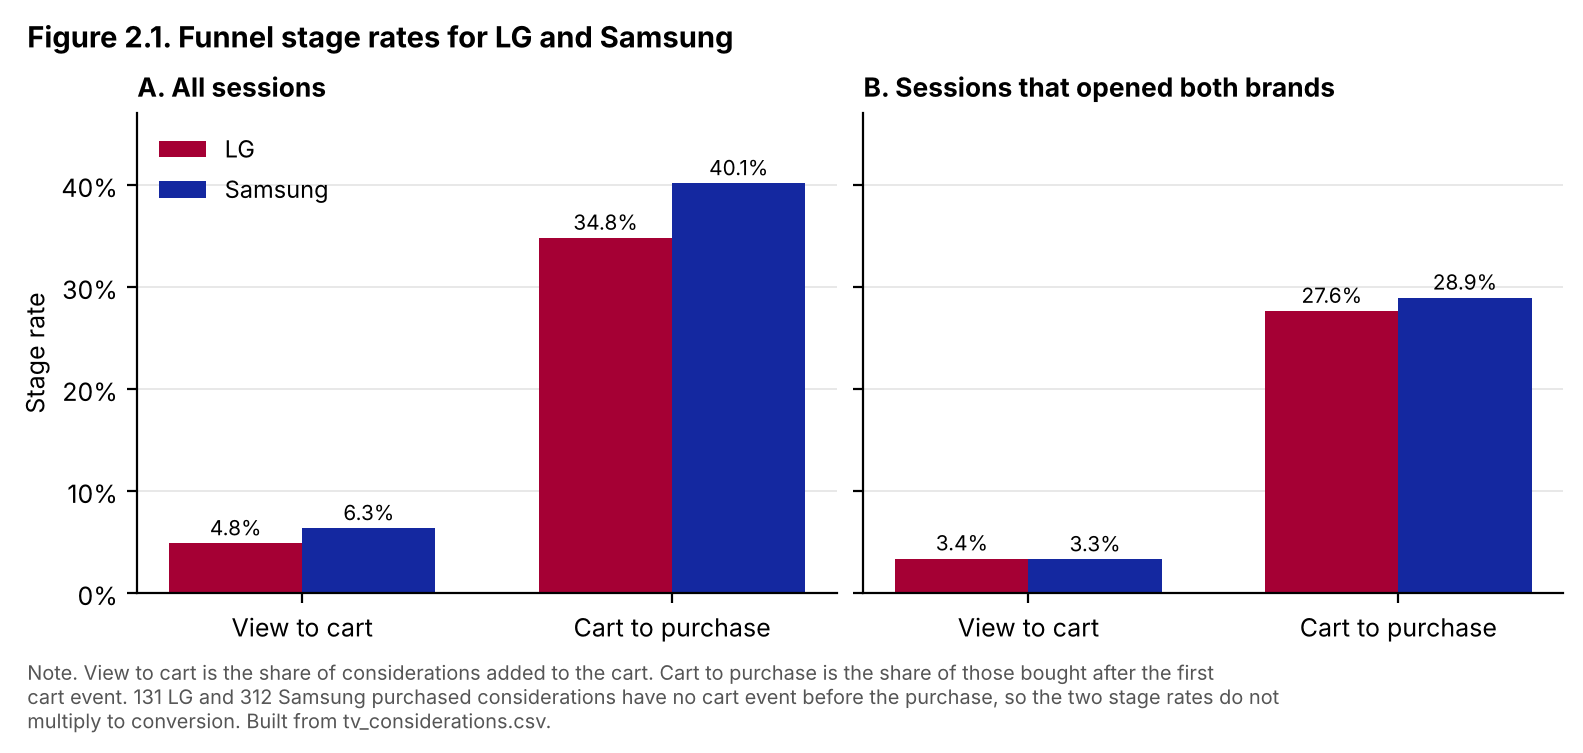

In [4]:
prec = []
for name, d in [('All LG and Samsung considerations', ls), ('Top models only', top),
                ('Models outside the top models', rest),
                ('Excluding considerations after an earlier recorded TV purchase', ls[ls['bought_tv_before'] == 0])]:
    gap, se = gap_se(d)
    p_wild, n_models = wild_p(d)
    pm = d.groupby(['brand', 'product_id'])['purchased'].agg(['mean', 'size']).reset_index()
    big = pm[pm['size'] >= 100]
    prec.append({'Sample': name, 'LG minus Samsung (pp)': gap,
                 'Gap, 95% CI low (pp)': gap - 1.96 * se['user_product'], 'Gap, 95% CI high (pp)': gap + 1.96 * se['user_product'],
                 'Standard error, clustered by user and by model (pp)': se['user_product'],
                 'Wild cluster bootstrap p, clustered by model': f'{p_wild:.3f}', 'Models in the sample': n_models,
                 'Standard error, clustered by model only (pp)': se['product'],
                 'Standard error, considerations independent (pp)': se['independent'],
                 'LG average model conversion, models equally weighted (%)': 100 * pm.loc[pm['brand'] == 'lg', 'mean'].mean(),
                 'Samsung average model conversion, models equally weighted (%)': 100 * pm.loc[pm['brand'] == 'samsung', 'mean'].mean(),
                 'LG models with 100 or more considerations': int((big['brand'] == 'lg').sum()),
                 'Samsung models with 100 or more considerations': int((big['brand'] == 'samsung').sum()),
                 'LG average conversion of those models, equally weighted (%)': 100 * big.loc[big['brand'] == 'lg', 'mean'].mean(),
                 'Samsung average conversion of those models, equally weighted (%)': 100 * big.loc[big['brand'] == 'samsung', 'mean'].mean()})
t25 = pd.DataFrame(prec).set_index('Sample')
save_table('2.5', 'Precision of the LG minus Samsung conversion gap, and the gap with models equally weighted', t25,
           'The gap, its interval and its main standard error come from a regression of the purchase indicator on an LG '
           'indicator, clustered by user and by model. The wild cluster bootstrap resamples models with Rademacher weights and '
           'the null hypothesis imposed, and it enumerates every sign pattern when a sample has 16 models or fewer. With 13 top '
           'models the clustered standard error is unreliable and the bootstrap p-value is the better guide. The averages with '
           'models equally weighted answer a different question from the gap, which weights each model by its considerations.',
           [F_CONS])

two_brand = ls.groupby(SESSION)['brand'].nunique().pipe(lambda s: s[s == 2].index)
ls['two_brand_session'] = ls.set_index(SESSION).index.isin(two_brand).astype(int)


def funnel(d):
    carts, pac = d['added_to_cart'].sum(), d['purchased_after_cart'].sum()
    return {'View to cart': 100 * carts / len(d), 'Cart to purchase': 100 * pac / carts,
            'no_cart': int(d['purchased'].sum() - pac)}


fun = {(s, br): funnel(ls[(ls['brand'] == br) & ((ls['two_brand_session'] == 1) if s == 'both' else True)])
       for s in ['all', 'both'] for br in ['lg', 'samsung']}
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.2), layout='constrained', sharey=True)
stages = ['View to cart', 'Cart to purchase']
for ax, s, title in [(axes[0], 'all', 'A. All sessions'), (axes[1], 'both', 'B. Sessions that opened both brands')]:
    x = np.arange(2)
    for j, br in enumerate(['lg', 'samsung']):
        vals = [fun[(s, br)][st] for st in stages]
        ax.bar(x + (j - 0.5) * 0.36, vals, 0.36, color=COLORS[br], label=NAMES[br])
        for xi, val in zip(x + (j - 0.5) * 0.36, vals):
            ax.text(xi, val + 0.8, f'{val:.1f}%', ha='center', fontsize=7.5)
    ax.set_xticks(x, stages)
    ax.set_ylim(0, 47)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(pct)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Stage rate')
axes[0].legend(loc='upper left')
save_figure(fig, '2.1', 'Funnel stage rates for LG and Samsung',
            'View to cart is the share of considerations added to the cart. Cart to purchase is the share of those bought '
            f"after the first cart event. {fun[('all', 'lg')]['no_cart']} LG and {fun[('all', 'samsung')]['no_cart']} Samsung "
            'purchased considerations have no cart event before the purchase, so the two stage rates do not multiply to '
            'conversion.', [F_CONS])

## 4. Browsing before the model is opened

Figure 2.2 groups LG and Samsung considerations by the TVs opened earlier in the same session and gives the conversion of each group. The other main brand is Samsung for an LG consideration and LG for a Samsung consideration. Table 2.6 covers the two flags on the user's earlier activity, a TV bought before this view (in this or an earlier session) and an earlier session in any category. Table 2.7 splits the conversion gap into a composition part, which arises because LG and Samsung considerations are spread differently across groups of shoppers, and a part that compares the two brands within the groups.

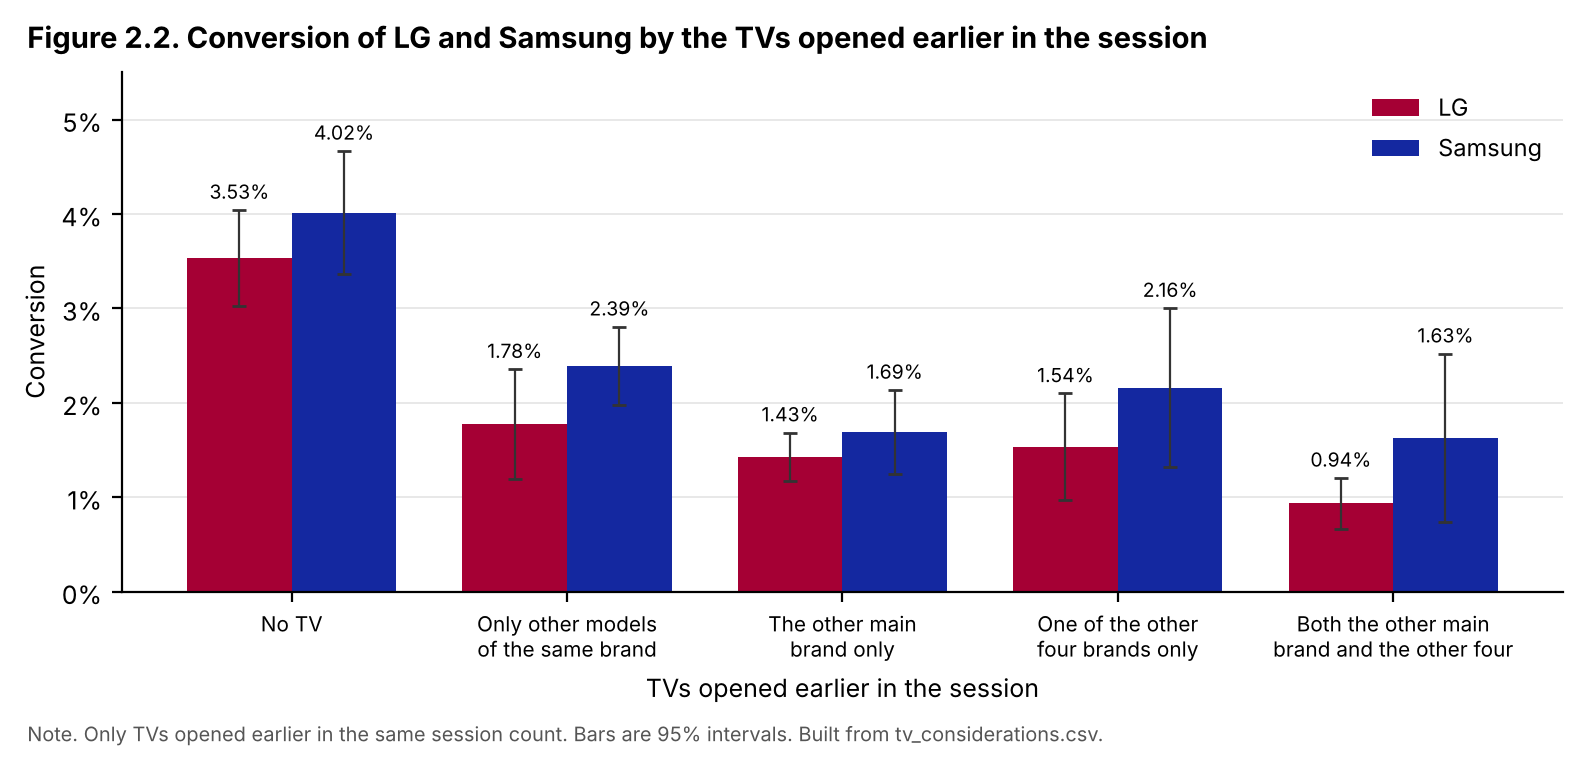

**Table 2.6. Conversion by the two flags on the user's earlier activity**

Considerations with the flag  Users with the flag  Share of considerations with the flag (%)  Conversion with the flag (%)  Conversion without the flag (%)  \
Flag                                     Brand                                                                                                                                                                  
Returning visitor                        LG                               4033                 1982                                      18.16                          2.88                             2.14   
                                         Samsung                          7327                 3664                                      13.96                          3.89                             3.01   
Earlier recorded TV purchase by the user LG                                239                  132                                       1.08                         25.94                             2.02   
                                         Samsung                           504                  304                                       0.96                         28.57                             2.89   

                                                  Difference (pp)  
Flag                                     Brand                     
Returning visitor                        LG                  0.74  
                                         Samsung             0.88  
Earlier recorded TV purchase by the user LG                 23.93  
                                         Samsung            25.68

*Note.* Across the six brands, 570 users opened a TV after an earlier recorded TV purchase. 93.4% of the purchased considerations that followed an earlier TV purchase were bought within five minutes of the first view, against 72.4% of the other purchased considerations. Built from tv_considerations.csv, events_clean.csv.

**Table 2.7. The LG minus Samsung conversion gap split into a composition part and a part within groups**

,Composition contribution (pp),Part within the observed groups (pp),Composition share of the raw gap (%),"Composition share, Samsung reweighted to LG's mix (%)",Groups compared,Samsung considerations in groups that also hold LG considerations (%),"Composition share, excluding considerations after an earlier recorded TV purchase (%)"
Groups defined by,,,,,,,
Another brand opened earlier in the session (yes or no),-0.35,-0.51,40.86,38.41,2,100.00,37.46
Position in the session (three groups),-0.32,-0.54,37.40,36.07,3,100.00,34.18
"Position, price band, month and returning visitor together",-0.30,-0.56,34.77,28.21,60,100.00,35.00


*Note.* The composition contribution is LG's conversion minus the conversion LG would have if its considerations were spread across the groups as Samsung's are. The other part compares the two brands within the observed groups and does not hold individual shoppers fixed. The second share does the reweighting the other way round. The last row uses every combination of the four characteristics as a group. The split is a descriptive reweighting and does not attribute the gap to causes. Built from tv_considerations.csv.

In [5]:
OB = ['No TV', 'Only other models of the same brand', 'The other main brand, none of the other four',
      'One of the other four brands, not the other main brand', 'Both the other main brand and one of the other four']
ls['opened_before'] = np.select(
    [ls['tvs_opened_before'] == 0, ls['other_brand_opened_before'] == 0,
     (ls['rival_opened_before'] == 1) & (ls['other_four_opened_before'] == 0),
     (ls['rival_opened_before'] == 0) & (ls['other_four_opened_before'] == 1)], OB[:4], OB[4])
ob_rates = rates(ls, ['opened_before', 'brand'])
fig, ax = plt.subplots(figsize=(7.8, 3.5), layout='constrained')
x = np.arange(len(OB))
for j, br in enumerate(['lg', 'samsung']):
    r = ob_rates.xs(br, level='brand').loc[OB]
    xx = x + (j - 0.5) * 0.38
    ax.bar(xx, r['rate_pct'], 0.38, color=COLORS[br], label=NAMES[br])
    ax.errorbar(xx, r['rate_pct'], yerr=[r['rate_pct'] - r['ci_low_pct'], r['ci_high_pct'] - r['rate_pct']], fmt='none',
                ecolor='#333333', elinewidth=0.8, capsize=2.5)
    for xi, (v, hi_) in enumerate(zip(r['rate_pct'], r['ci_high_pct'])):
        ax.text(xx[xi], hi_ + 0.12, f'{v:.2f}%', ha='center', fontsize=7)
ax.set_xticks(x, ['No TV', 'Only other models\nof the same brand', 'The other main\nbrand only',
                  'One of the other\nfour brands only', 'Both the other main\nbrand and the other four'], fontsize=7.5)
ax.set_ylim(0, ob_rates['ci_high_pct'].max() * 1.18)
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel('Conversion')
ax.set_xlabel('TVs opened earlier in the session')
ax.legend()
ax.grid(axis='x', visible=False)
save_figure(fig, '2.2', 'Conversion of LG and Samsung by the TVs opened earlier in the session',
            'Only TVs opened earlier in the same session count. Bars are 95% intervals.', [F_CONS])

rows_ = []
for col, lab in [('returning_visitor', 'Returning visitor'), ('bought_tv_before', 'Earlier recorded TV purchase by the user')]:
    for g in ['lg', 'samsung']:
        d = ls[ls['brand'] == g]
        c0, c1 = d.loc[d[col] == 0, 'purchased'], d.loc[d[col] == 1, 'purchased']
        rows_.append({'Flag': lab, 'Brand': NAMES[g], 'Considerations with the flag': len(c1),
                      'Users with the flag': d.loc[d[col] == 1, 'user_id'].nunique(),
                      'Share of considerations with the flag (%)': 100 * d[col].mean(),
                      'Conversion with the flag (%)': 100 * c1.mean(), 'Conversion without the flag (%)': 100 * c0.mean(),
                      'Difference (pp)': 100 * (c1.mean() - c0.mean())})
t27 = pd.DataFrame(rows_).set_index(['Flag', 'Brand'])
own_buy = (pe[KEY + ['event_time']].merge(cons[KEY + ['first_view', 'bought_tv_before']], on=KEY)
           .query('event_time >= first_view').groupby(KEY + ['first_view', 'bought_tv_before'])['event_time'].min().reset_index())
fast = 100 * (own_buy['event_time'] - own_buy['first_view'] <= pd.Timedelta(minutes=5)).groupby(own_buy['bought_tv_before']).mean()
save_table('2.6', "Conversion by the two flags on the user's earlier activity", t27,
           f"Across the six brands, {cons.loc[cons['bought_tv_before'] == 1, 'user_id'].nunique():,} users opened a TV after "
           f'an earlier recorded TV purchase. {fast[1]:.1f}% of the purchased considerations that followed an earlier TV '
           f'purchase were bought within five minutes of the first view, against {fast[0]:.1f}% of the other purchased '
           'considerations.', [F_CONS, F_EV])


def mix_split(d, cols):
    lg, sm = d[d['brand'] == 'lg'], d[d['brand'] == 'samsung']
    rl, rs = lg.groupby(cols, observed=True)['purchased'].mean(), sm.groupby(cols, observed=True)['purchased'].mean()
    wl, ws = lg.groupby(cols, observed=True).size() / len(lg), sm.groupby(cols, observed=True).size() / len(sm)
    common = rl.index.intersection(rs.index)
    lg_at_sm_mix = (ws[common] * rl[common]).sum() / ws[common].sum()
    sm_at_lg_mix = (wl[common] * rs[common]).sum() / wl[common].sum()
    LG, SM = lg['purchased'].mean(), sm['purchased'].mean()
    return {'Composition contribution (pp)': 100 * (LG - lg_at_sm_mix),
            'Part within the observed groups (pp)': 100 * (lg_at_sm_mix - SM),
            'Composition share of the raw gap (%)': 100 * (LG - lg_at_sm_mix) / (LG - SM),
            "Composition share, Samsung reweighted to LG's mix (%)": 100 * (sm_at_lg_mix - SM) / (LG - SM),
            'Groups compared': len(common),
            'Samsung considerations in groups that also hold LG considerations (%)': 100 * ws[common].sum()}


SPLITS = [('Another brand opened earlier in the session (yes or no)', ['other_brand_opened_before']),
          ('Position in the session (three groups)', ['position_in_session']),
          ('Position, price band, month and returning visitor together',
           ['position_in_session', 'price_band', 'month', 'returning_visitor'])]
mix = []
for name, cols in SPLITS:
    r = {'Groups defined by': name, **mix_split(ls, cols)}
    r['Composition share, excluding considerations after an earlier recorded TV purchase (%)'] = mix_split(
        ls[ls['bought_tv_before'] == 0], cols)['Composition share of the raw gap (%)']
    mix.append(r)
t28 = pd.DataFrame(mix).set_index('Groups defined by')
save_table('2.7', 'The LG minus Samsung conversion gap split into a composition part and a part within groups', t28,
           "The composition contribution is LG's conversion minus the conversion LG would have if its considerations were "
           "spread across the groups as Samsung's are. The other part compares the two brands within the observed groups and "
           'does not hold individual shoppers fixed. The second share does the reweighting the other way round. The last row '
           'uses every combination of the four characteristics as a group. The split is a descriptive reweighting and does not '
           'attribute the gap to causes.', [F_CONS])

## 5. Movement between brands

Table 2.8 looks at the sessions that opened both LG and Samsung, which brand was opened first and which brands were bought, counting each session once. Table 2.9 classifies what shoppers bought after opening a model when no other brand had been opened before it. Figure 2.3 follows each session from the first TV opened.

**Table 2.8. Sessions that opened both LG and Samsung: which brand came first and which was bought**

Number of sessions  Share of the sessions (%)  Share, 95% CI low (%)  Share, 95% CI high (%)  \
Sessions                                      Brand opened first                                                                                                   
All sessions that opened both brands          LG opened first                     1843                      30.17                  29.02                   31.32   
                                              Samsung opened first                4266                      69.83                  68.68                   70.98   
Sessions with exactly one model of each brand LG opened first                      726                      36.50                  34.39                   38.61   
                                              Samsung opened first                1263                      63.50                  61.39                   65.61   

                                                                    Share expected if each shopper's models came in random order (%)  Bought LG, not Samsung (%)  Bought LG, not Samsung, 95% CI low (%)  \
Sessions                                      Brand opened first                                                                                                                                           
All sessions that opened both brands          LG opened first                                                                  45.36                        1.52                                    0.96   
                                              Samsung opened first                                                             54.64                        1.88                                    1.47   
Sessions with exactly one model of each brand LG opened first                                                                  50.00                        0.96                                    0.25   
                                              Samsung opened first                                                             50.00                        2.45                                    1.60   

                                                                    Bought LG, not Samsung, 95% CI high (%)  Bought Samsung, not LG (%)  Bought Samsung, not LG, 95% CI low (%)  Bought Samsung, not LG, 95% CI high (%)  \
Sessions                                      Brand opened first                                                                                                                                                           
All sessions that opened both brands          LG opened first                                          2.08                        2.71                                    1.97                                     3.46   
                                              Samsung opened first                                     2.28                        2.25                                    1.81                                     2.69   
Sessions with exactly one model of each brand LG opened first                                          1.68                        3.44                                    2.12                                     4.77   
                                              Samsung opened first                                     3.31                        1.35                                    0.71                                     1.98   

                                                                    Bought both (%)  Bought neither (%)  Bought a TV of the other four brands (%)  
Sessions                                      Brand opened first                                                                                   
All sessions that opened both brands          LG opened first                  0.16               95.60                                      0.49  
                                              Samsung opened first             0.21          

*Note.* Each session is counted once, and a purchase anywhere in the session counts. The random-order benchmark keeps the LG and Samsung models each shopper opened and assumes their order could have been shuffled, which removes the advantage Samsung gets from shoppers opening more Samsung models. Across 2,000 random orders, the share of sessions opening Samsung first ranges from 53.45% to 55.85% (2.5th to 97.5th percentiles). The benchmark describes the data and says nothing about placement. Built from tv_considerations.csv, events_clean.csv.

**Table 2.9. What was bought after a TV model was opened, when no other brand had been opened before it**

,LG (%),Samsung (%),Other four brands (%)
"What the shopper bought after opening this model, same session",,,
Bought this model,3.00,3.49,3.81
Bought an LG TV,0.00,0.28,0.12
Bought a Samsung TV,0.36,0.00,0.49
Bought a TV of the other four brands,0.18,0.34,0.90
Bought another model of the same brand,1.24,1.70,0.80
Bought no TV,95.22,94.20,93.88
Considerations,"12,598.00","40,757.00","25,123.00"


*Note.* Each consideration takes the first label that applies in the order listed (this model, then the first other brand bought, then another model of the same brand), so a session with several considerations can count one purchase more than once. Built from tv_considerations.csv.

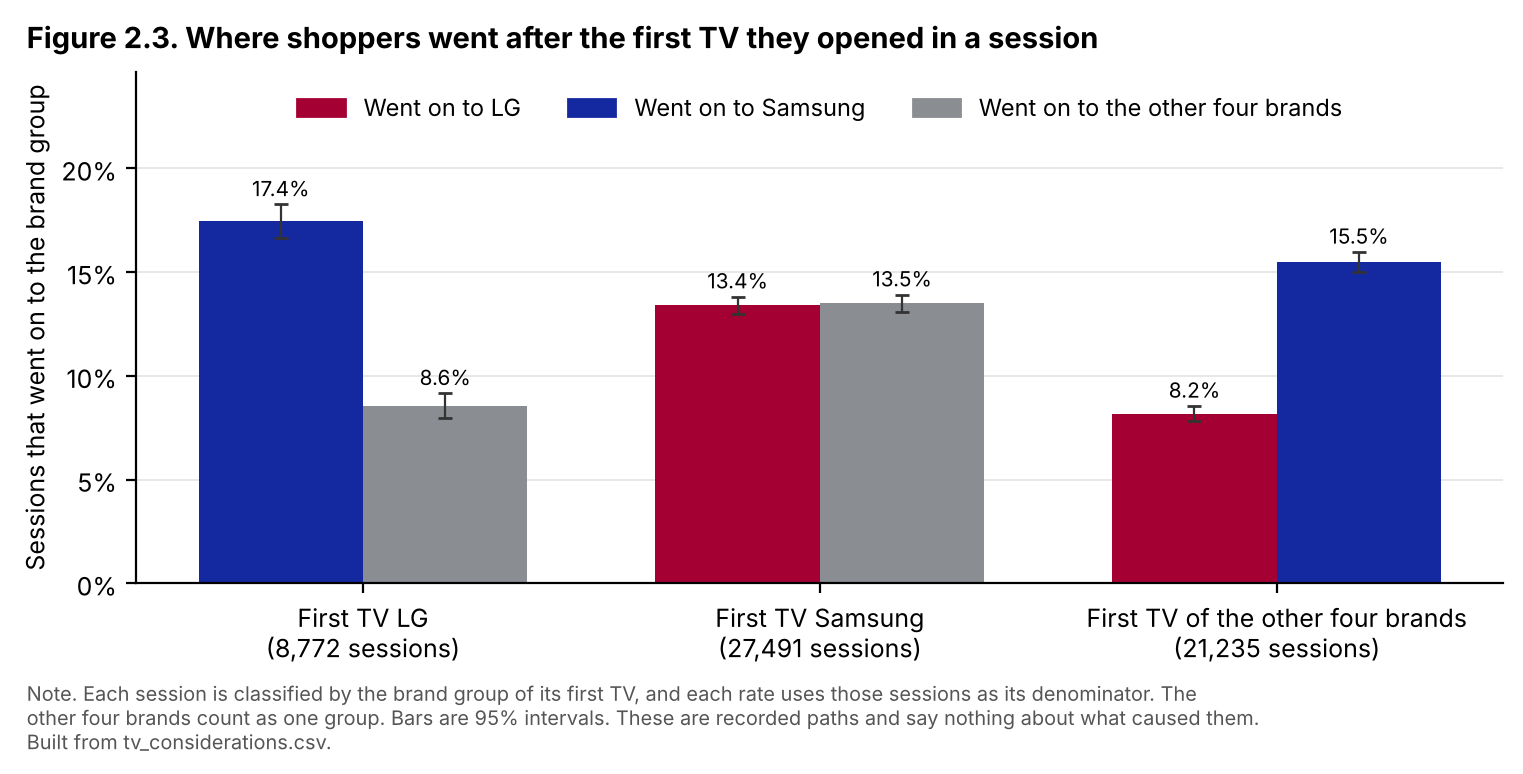

In [6]:
sess = (cons.sort_values('first_view', kind='stable').groupby(SESSION)
        .agg(first_group=('brand_group', 'first'),
             n_lg=('brand_group', lambda s: (s == 'lg').sum()), n_sm=('brand_group', lambda s: (s == 'samsung').sum()),
             n_o4=('brand_group', lambda s: (s == 'other_four').sum())))
pe_g = pe.assign(g=np.where(pe['brand'].isin(['lg', 'samsung']), pe['brand'], 'other_four'))
both = pd.concat([ls[ls['brand'] == 'lg'].groupby(SESSION)['first_view'].min().rename('lg'),
                  ls[ls['brand'] == 'samsung'].groupby(SESSION)['first_view'].min().rename('samsung')], axis=1).dropna()
both = both.join(sess[['n_lg', 'n_sm']])
both['samsung_first'] = (both['samsung'] < both['lg']).astype(int)
pb = pe_g.groupby(SESSION + ['g']).size().unstack().reindex(both.index).reindex(columns=GROUPS).fillna(0) > 0
both['lg_not_sm'], both['sm_not_lg'] = (pb['lg'] & ~pb['samsung']).astype(int), (pb['samsung'] & ~pb['lg']).astype(int)
both['both'], both['neither'] = (pb['lg'] & pb['samsung']).astype(int), (~pb['lg'] & ~pb['samsung']).astype(int)
both['o4'] = pb['other_four'].astype(int)
expected = both['n_sm'] / (both['n_sm'] + both['n_lg'])
sims = (np.random.default_rng(2026).random((2000, len(both))) < expected.to_numpy()).mean(axis=1)
one_each = both[(both['n_lg'] == 1) & (both['n_sm'] == 1)]
rows_ = []
for grp_name, grp, exp_sm in [('All sessions that opened both brands', both, 100 * expected.mean()),
                              ('Sessions with exactly one model of each brand', one_each, 50.0)]:
    u = grp.index.get_level_values('user_id')
    for first_name, flag, exp in [('LG opened first', 0, 100 - exp_sm), ('Samsung opened first', 1, exp_sm)]:
        share, lo_, hi_ = mean_ci((grp['samsung_first'] == flag).astype(int), u)
        d = grp[grp['samsung_first'] == flag]
        du = d.index.get_level_values('user_id')
        r = {'Sessions': grp_name, 'Brand opened first': first_name, 'Number of sessions': len(d),
             'Share of the sessions (%)': share, 'Share, 95% CI low (%)': lo_, 'Share, 95% CI high (%)': hi_,
             "Share expected if each shopper's models came in random order (%)": exp}
        for col, lab in [('lg_not_sm', 'Bought LG, not Samsung'), ('sm_not_lg', 'Bought Samsung, not LG')]:
            m, l2, h2 = mean_ci(d[col], du)
            r[f'{lab} (%)'], r[f'{lab}, 95% CI low (%)'], r[f'{lab}, 95% CI high (%)'] = m, l2, h2
        r['Bought both (%)'] = 100 * d['both'].mean()
        r['Bought neither (%)'] = 100 * d['neither'].mean()
        r['Bought a TV of the other four brands (%)'] = 100 * d['o4'].mean()
        rows_.append(r)
t29 = pd.DataFrame(rows_).set_index(['Sessions', 'Brand opened first'])
save_table('2.8', 'Sessions that opened both LG and Samsung: which brand came first and which was bought', t29,
           'Each session is counted once, and a purchase anywhere in the session counts. The random-order benchmark keeps the '
           'LG and Samsung models each shopper opened and assumes their order could have been shuffled, which removes the '
           'advantage Samsung gets from shoppers opening more Samsung models. Across 2,000 random orders, the share of sessions '
           f'opening Samsung first ranges from {100 * np.percentile(sims, 2.5):.2f}% to {100 * np.percentile(sims, 97.5):.2f}% '
           '(2.5th to 97.5th percentiles). The benchmark describes the data and says nothing about placement.',
           [F_CONS, F_EV])

fresh = cons[cons['other_brand_opened_before'] == 0]
order_ = ['bought_this_model', 'bought_lg', 'bought_samsung', 'bought_other_four', 'bought_other_model_same_brand', 'bought_nothing']
t210 = (pd.crosstab(fresh['session_result'], fresh['brand_group'], normalize='columns') * 100).reindex(order_).fillna(0)[GROUPS]
t210.columns = [f'{NAMES[g]} (%)' for g in GROUPS]
t210.index = [RESULT[i] for i in t210.index]
t210.loc['Considerations'] = fresh['brand_group'].value_counts()[GROUPS].values
t210.index.name = 'What the shopper bought after opening this model, same session'
save_table('2.9', 'What was bought after a TV model was opened, when no other brand had been opened before it', t210,
           'Each consideration takes the first label that applies in the order listed (this model, then the first other brand '
           'bought, then another model of the same brand), so a session with several considerations can count one purchase more '
           'than once.', [F_CONS])

rate_cols = {'lg': 'n_lg', 'samsung': 'n_sm', 'other_four': 'n_o4'}
fig, ax = plt.subplots(figsize=(7.5, 3.3), layout='constrained')
ymax = 0
for i, src_g in enumerate(GROUPS):
    d = sess[sess['first_group'] == src_g]
    u = d.index.get_level_values('user_id')
    for j, dst in enumerate([g for g in GROUPS if g != src_g]):
        val, lo_r, hi_r = mean_ci((d[rate_cols[dst]] > 0).astype(int), u)
        xx = i + (j - 0.5) * 0.36
        ax.bar(xx, val, 0.36, color=COLORS[dst])
        ax.errorbar(xx, val, yerr=[[val - lo_r], [hi_r - val]], fmt='none', ecolor='#333333', elinewidth=0.8, capsize=2.5)
        ax.text(xx, hi_r + 0.4, f'{val:.1f}%', ha='center', fontsize=7.5)
        ymax = max(ymax, hi_r)
LOWER = {'lg': 'LG', 'samsung': 'Samsung', 'other_four': 'the other four brands'}
ax.set_xticks(range(3), [f"First TV {'of ' if g == 'other_four' else ''}{LOWER[g]}\n({(sess['first_group'] == g).sum():,} sessions)"
                         for g in GROUPS])
ax.set_ylabel('Sessions that went on to the brand group')
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, ymax * 1.35)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in GROUPS], [f'Went on to {LOWER[g]}' for g in GROUPS],
          loc='upper center', ncol=3)
ax.grid(axis='x', visible=False)
save_figure(fig, '2.3', 'Where shoppers went after the first TV they opened in a session',
            'Each session is classified by the brand group of its first TV, and each rate uses those sessions as its '
            'denominator. The other four brands count as one group. Bars are 95% intervals. These are recorded paths and say '
            'nothing about what caused them.', [F_CONS])

## 6. Reach and the top models

LG's purchased considerations, like Samsung's, equal the number of sessions reaching the brand times the considerations per reaching session times the conversion per consideration. Figure 2.4 splits LG's shortfall against Samsung among the three factors, and Table 2.10 repeats the split in other ways. Tables 2.11 to 2.13 describe how concentrated each brand's traffic is in a few models, using the top models defined in the dictionary.

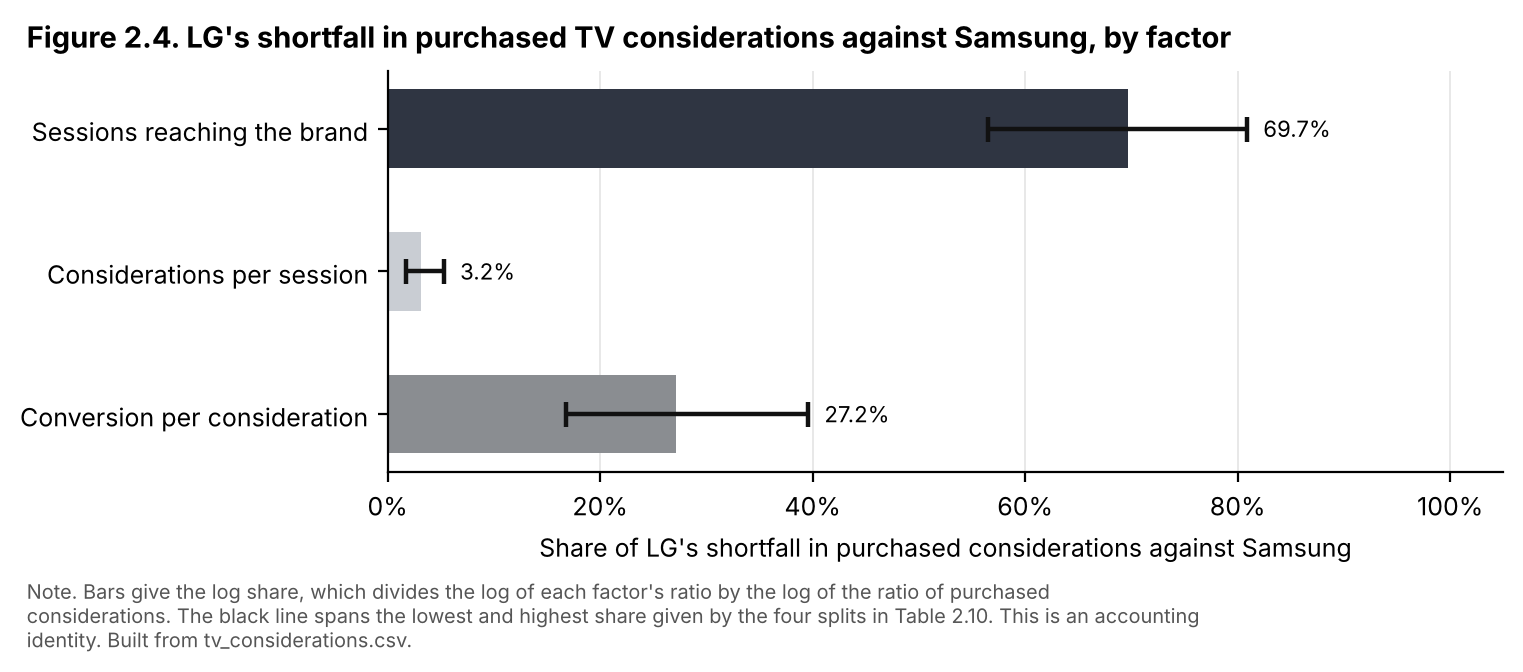

**Table 2.10. LG's shortfall split among the three factors in other ways**

,LG,Samsung,LG / Samsung,Shapley share (%),LG given only this Samsung factor (%),Samsung given only this LG factor (%),"Log share, excluding considerations after an earlier recorded TV purchase (%)","Log share, models outside the top models (%)"
Factor,,,,,,,,
Sessions reaching the brand,"14,193.00","32,308.00",0.44,68.59,56.54,80.91,67.48,80.62
Considerations per session,1.57,1.62,0.96,3.37,1.70,5.32,3.10,-5.40
Conversion per consideration (%),2.27,3.13,0.73,28.04,16.76,39.60,29.42,24.77
Total,NaN,NaN,NaN,100.00,74.99,125.83,100.00,100.00


*Note.* The Shapley share averages, over the six orders in which LG's three values can be replaced by Samsung's, the purchased considerations each replacement adds. The next two columns replace one factor only, starting from LG or from Samsung, and their totals differ from 100 because the factors multiply. The last two columns repeat the log share on two subsamples. With conversion taken as a proportion (2.27% as 0.0227), the product of the three factors equals the purchased TV considerations of each brand in Table 0.4 of 00_scope_and_methodology_rationale.ipynb. Built from tv_considerations.csv.

**Table 2.11. Considerations per model and conversion by price band, LG and Samsung**

,"LG, models","Samsung, models","LG, considerations","Samsung, considerations","LG, median considerations","Samsung, median considerations","LG, purchases","Samsung, purchases","LG, considerations per model","Samsung, considerations per model","LG, conversion (%)","Samsung, conversion (%)"
Median price of the model,,,,,,,,,,,,
Under 300,3,7,2844,6699,105.00,41.00,64,186,948.00,957.00,2.25,2.78
300 to 450,8,8,6325,14132,440.00,61.00,164,597,790.62,"1,766.50",2.59,4.22
450 to 650,25,18,7045,20953,144.00,401.50,182,663,281.80,"1,164.06",2.58,3.16
"650 to 1,000",31,22,3668,4833,61.00,55.00,66,100,118.32,219.68,1.80,2.07
"Over 1,000",38,36,2331,5882,37.50,94.00,29,99,61.34,163.39,1.24,1.68


*Note.* Each model is placed in the band of its median price at the first view. Built from tv_considerations.csv.

... (2 outputs left out)

*Note.* The difference between Samsung's and LG's top models accounts for 62% of the brands' total gap in considerations and 73% of the gap in purchased considerations. Built from tv_considerations.csv.

**Table 2.13. The top-model rule and three alternatives**

,LG top models,LG same models as the rule used,LG smallest share among top models (%),LG largest share among other models (%),Samsung top models,Samsung same models as the rule used,Samsung smallest share among top models (%),Samsung largest share among other models (%)
Rule,,,,,,,,
At least 3% of the brand,7,yes,4.55,2.99,9,no,3.28,2.95
At least 4% of the brand (rule used),7,yes,4.55,2.99,6,yes,5.43,3.44
At least 5% of the brand,5,no,5.02,4.61,6,yes,5.43,3.44
Ten most-considered models of each brand,10,no,2.49,1.95,10,no,2.95,2.35


*Note.* Shares are each model's share of its brand's considerations over the two months. Table 2.12 describes the top models under the rule used. Built from tv_considerations.csv.

In [7]:
FACTORS = ['sessions', 'per_session', 'conversion']


def factors(d):
    k = d.groupby('brand').agg(purchases=('purchased', 'sum'), considerations=('purchased', 'size'))
    k['sessions'] = d[SESSION + ['brand']].drop_duplicates().groupby('brand').size()
    k['per_session'] = k['considerations'] / k['sessions']
    k['conversion'] = 100 * k['purchases'] / k['considerations']
    return k


def shares(k):
    L, S = k.loc['lg', FACTORS].to_numpy(float), k.loc['samsung', FACTORS].to_numpy(float)
    gap, idx = S.prod() - L.prod(), np.arange(3)
    log = np.log(S / L) / np.log(S.prod() / L.prod())
    shapley = np.zeros(3)
    for order_ in itertools.permutations(range(3)):
        cur = L.copy()
        for i in order_:
            before = cur.prod()
            cur[i] = S[i]
            shapley[i] += cur.prod() - before
    lg_gets = np.array([np.where(idx == i, S, L).prod() - L.prod() for i in range(3)])
    sm_loses = np.array([S.prod() - np.where(idx == i, L, S).prod() for i in range(3)])
    return 100 * log, 100 * shapley / 6 / gap, 100 * lg_gets / gap, 100 * sm_loses / gap


k = factors(ls)
log_sh, shap_sh, lg_sh, sm_sh = shares(k)
fig, ax = plt.subplots(figsize=(7.5, 2.8), layout='constrained')
alt = np.column_stack([log_sh, shap_sh, lg_sh, sm_sh])
yy = np.arange(3)
ax.barh(yy, log_sh, color=['#2F3542', '#C9CDD3', '#8A8D91'], height=0.55)
ax.hlines(yy, alt.min(axis=1), alt.max(axis=1), color='#111111', lw=1.6, zorder=3)
ax.plot(alt.min(axis=1), yy, '|', color='#111111', ms=9, mew=1.6, zorder=3)
ax.plot(alt.max(axis=1), yy, '|', color='#111111', ms=9, mew=1.6, zorder=3)
for i, (sh, hi_) in enumerate(zip(log_sh, alt.max(axis=1))):
    ax.text(max(sh, hi_) + 1.5, i, f'{sh:.1f}%', va='center', fontsize=8)
ax.set_yticks(yy, ['Sessions reaching the brand', 'Considerations per session', 'Conversion per consideration'])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("Share of LG's shortfall in purchased considerations against Samsung")
ax.grid(axis='y', visible=False)
save_figure(fig, '2.4', "LG's shortfall in purchased TV considerations against Samsung, by factor",
            "Bars give the log share, which divides the log of each factor's ratio by the log of the ratio of purchased "
            'considerations. The black line spans the lowest and highest share given by the four splits in Table 2.10. This is '
            'an accounting identity.', [F_CONS])

t212 = pd.DataFrame({'LG': k.loc['lg', FACTORS].to_numpy(float), 'Samsung': k.loc['samsung', FACTORS].to_numpy(float)})
t212['LG / Samsung'] = t212['LG'] / t212['Samsung']
for name, v_ in [('Shapley share (%)', shap_sh), ('LG given only this Samsung factor (%)', lg_sh),
                 ('Samsung given only this LG factor (%)', sm_sh),
                 ('Log share, excluding considerations after an earlier recorded TV purchase (%)',
                  shares(factors(ls[ls['bought_tv_before'] == 0]))[0]),
                 ('Log share, models outside the top models (%)', shares(factors(rest))[0])]:
    t212[name] = v_
t212.loc[3] = [np.nan, np.nan, np.nan] + list(t212.iloc[:, 3:].sum())
t212.index = ['Sessions reaching the brand', 'Considerations per session', 'Conversion per consideration (%)', 'Total']
t212.index.name = 'Factor'
save_table('2.10', "LG's shortfall split among the three factors in other ways", t212,
           "The Shapley share averages, over the six orders in which LG's three values can be replaced by Samsung's, the "
           'purchased considerations each replacement adds. The next two columns replace one factor only, starting from LG or '
           'from Samsung, and their totals differ from 100 because the factors multiply. The last two columns repeat the log '
           'share on two subsamples. With conversion taken as a proportion (2.27% as 0.0227), the product of the three factors '
           'equals the purchased TV considerations of each brand in Table 0.4 of 00_scope_and_methodology_rationale.ipynb.',
           [F_CONS])

prod = ls.groupby(['brand', 'product_id']).agg(considerations=('purchased', 'size'), purchases=('purchased', 'sum'),
                                               price=('price', 'median')).reset_index()
prod['band'] = pd.cut(prod['price'], BANDS, labels=BAND_NAMES)
pb2 = prod.groupby(['band', 'brand'], observed=True).agg(models=('product_id', 'size'), considerations=('considerations', 'sum'),
                                                         median_considerations=('considerations', 'median'),
                                                         purchases=('purchases', 'sum'))
pb2['considerations_per_model'] = pb2['considerations'] / pb2['models']
pb2['conversion_pct'] = 100 * pb2['purchases'] / pb2['considerations']
t213 = pb2.unstack('brand')
t213.columns = [f"{NAMES[br]}, {m.replace('_', ' ').replace('pct', '(%)')}" for m, br in t213.columns]
t213.index.name = 'Median price of the model'
save_table('2.11', 'Considerations per model and conversion by price band, LG and Samsung', t213,
           'Each model is placed in the band of its median price at the first view.', [F_CONS])

tm = {}
for part, d in [('top models', top), ('other models', rest)]:
    for br in ['lg', 'samsung']:
        x_, allb = d[d['brand'] == br], ls[ls['brand'] == br]
        tm[f'{NAMES[br]}, {part}'] = {
            'Models': x_['product_id'].nunique(), 'Considerations': len(x_),
            "Share of the brand's considerations (%)": 100 * len(x_) / len(allb),
            'Considerations per model': len(x_) / x_['product_id'].nunique(),
            'Sessions that opened one of these models': x_[SESSION].drop_duplicates().shape[0],
            'Purchased considerations': int(x_['purchased'].sum()),
            "Share of the brand's purchased considerations (%)": 100 * x_['purchased'].sum() / allb['purchased'].sum(),
            'Conversion (%)': 100 * x_['purchased'].mean(), 'Median price at the first view': x_['price'].median()}
t214 = pd.DataFrame(tm)
t214.index.name = 'Measure'
n_ = lambda d, br: (d['brand'] == br).sum()
gap_cons = 100 * (n_(top, 'samsung') - n_(top, 'lg')) / (n_(ls, 'samsung') - n_(ls, 'lg'))
gap_buys = 100 * (top.loc[top['brand'] == 'samsung', 'purchased'].sum() - top.loc[top['brand'] == 'lg', 'purchased'].sum()) / (
    ls.loc[ls['brand'] == 'samsung', 'purchased'].sum() - ls.loc[ls['brand'] == 'lg', 'purchased'].sum())
save_table('2.12', 'Top models and all other models, LG and Samsung', t214,
           f"The difference between Samsung's and LG's top models accounts for {gap_cons:.0f}% of the brands' total gap in "
           f'considerations and {gap_buys:.0f}% of the gap in purchased considerations.', [F_CONS])

sel = models.join(ls.groupby('product_id')[['brand', 'model_rank_in_brand']].first())
RULES = [('At least 3% of the brand', lambda d: d['model_share_of_brand_pct'] >= 3),
         (f'At least {TOP_SHARE:g}% of the brand (rule used)', lambda d: d['model_share_of_brand_pct'] >= TOP_SHARE),
         ('At least 5% of the brand', lambda d: d['model_share_of_brand_pct'] >= 5),
         ('Ten most-considered models of each brand', lambda d: d['model_rank_in_brand'] <= 10)]
rows_ = []
for label, rule in RULES:
    r = {'Rule': label}
    for br in ['lg', 'samsung']:
        d = sel[sel['brand'] == br]
        s_ = rule(d)
        r[f'{NAMES[br]} top models'] = int(s_.sum())
        r[f'{NAMES[br]} same models as the rule used'] = 'yes' if s_.equals(d['top_model'] == 1) else 'no'
        r[f'{NAMES[br]} smallest share among top models (%)'] = d.loc[s_, 'model_share_of_brand_pct'].min()
        r[f'{NAMES[br]} largest share among other models (%)'] = d.loc[~s_, 'model_share_of_brand_pct'].max()
    rows_.append(r)
t215 = pd.DataFrame(rows_).set_index('Rule')
save_table('2.13', 'The top-model rule and three alternatives', t215,
           "Shares are each model's share of its brand's considerations over the two months. Table 2.12 describes the top "
           'models under the rule used.', [F_CONS])

## 7. Key measures for the report

Table 2.14 brings together, for LG and Samsung, the share of considerations bought, the median price and the browsing history known at the first view. Table 2.15 splits each brand's considerations by whether a TV of another brand was opened earlier in the session and gives the conversion in each group. The report's Tables 1 and 2 are built from them.

In [8]:
g = ls.groupby('brand_group')
t216 = pd.DataFrame({
    'Bought this model (%)': g['purchased'].mean() * 100,
    'Price at first view (median)': g['price'].median(),
    'First TV opened in session (%)': g['position_in_session'].apply(lambda s: (s == 'first_tv').mean() * 100),
    'TV models opened earlier (mean)': g['tvs_opened_before'].mean(),
    'Rival main brand opened earlier (%)': g['rival_opened_before'].mean() * 100,
    'Another own-brand model opened earlier (%)': g['own_other_model_opened_before'].mean() * 100,
    'One of the other four brands opened earlier (%)': g['other_four_opened_before'].mean() * 100,
    'Returning visitor (%)': g['returning_visitor'].mean() * 100,
    'Previous TV purchase recorded (%)': g['bought_tv_before'].mean() * 100,
    'Top-model considerations (%)': g['top_model'].mean() * 100,
}).T.rename(columns={'lg': 'LG', 'samsung': 'Samsung'})
t216.index.name = 'Measure'
save_table('2.14', 'Key measures for LG and Samsung TV considerations', t216,
           'The share bought is the outcome and the top-model share is retrospective. The other measures are known at the '
           'first view.', [F_CONS])

grp = ls.assign(group=ls['other_brand_opened_before'].map({0: 'No', 1: 'Yes'}))
n = grp.groupby(['group', 'brand_group']).size().unstack()
bought = grp.groupby(['group', 'brand_group'])['purchased'].sum().unstack()
n.loc['All'], bought.loc['All'] = n.sum(), bought.sum()
conv = bought / n * 100
t217 = pd.DataFrame({
    'LG considerations': n['lg'],
    'Samsung considerations': n['samsung'],
    'LG mix (%)': n['lg'] / n.loc['All', 'lg'] * 100,
    'Samsung mix (%)': n['samsung'] / n.loc['All', 'samsung'] * 100,
    'LG purchased': bought['lg'],
    'Samsung purchased': bought['samsung'],
    'LG conversion (%)': conv['lg'],
    'Samsung conversion (%)': conv['samsung'],
    'Gap (pp)': conv['lg'] - conv['samsung'],
})
t217.index.name = 'Another brand opened earlier'
save_table('2.15', 'LG and Samsung conversion by whether another brand was opened earlier in the session', t217,
           'Another brand covers the other main brand and the other four brands. The gap is LG minus Samsung, in '
           'percentage points.', [F_CONS])

**Table 2.14. Key measures for LG and Samsung TV considerations**

brand_group,LG,Samsung
Measure,,
Bought this model (%),2.27,3.13
Price at first view (median),460.84,493.96
First TV opened in session (%),39.49,52.36
TV models opened earlier (mean),1.92,1.23
Rival main brand opened earlier (%),36.25,11.62
Another own-brand model opened earlier (%),36.10,38.46
One of the other four brands opened earlier (%),18.10,14.37
Returning visitor (%),18.16,13.96
Previous TV purchase recorded (%),1.08,0.96


*Note.* The share bought is the outcome and the top-model share is retrospective. The other measures are known at the first view. Built from tv_considerations.csv.

**Table 2.15. LG and Samsung conversion by whether another brand was opened earlier in the session**

,LG considerations,Samsung considerations,LG mix (%),Samsung mix (%),LG purchased,Samsung purchased,LG conversion (%),Samsung conversion (%),Gap (pp)
Another brand opened earlier,,,,,,,,,
No,12598,40757,56.71,77.63,378,1421,3.00,3.49,-0.49
Yes,9615,11742,43.29,22.37,127,224,1.32,1.91,-0.59
All,22213,52499,100.00,100.00,505,1645,2.27,3.13,-0.86


*Note.* Another brand covers the other main brand and the other four brands. The gap is LG minus Samsung, in percentage points. Built from tv_considerations.csv.

In [9]:
pd.DataFrame(EXHIBITS).to_csv(OUT / 'exhibit_index.csv', index=False)
print(f"Saved {len(EXHIBITS)} exhibits to {OUT}")

Saved 19 exhibits to results/preliminary
